# Lab 2 Modeling and Simulation of a Furuta Pendulum
#### This notebook contains code snippets to plot the data from the Furuta pendulum experiment, and to calculate the LQR gain vector for the double pendulum controller.

## Task 1 - Tune the dampening constants
#### We have gathered some data from a real furuta pendulum. The pendulum was dropped at an almost upright position and the resulting angles of the rotor and pendulum logged. Run the code below to load and plot the data.

Text(0, 0.5, 'radians')

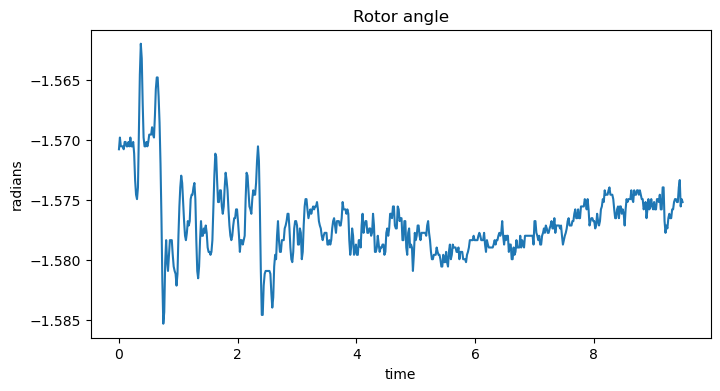

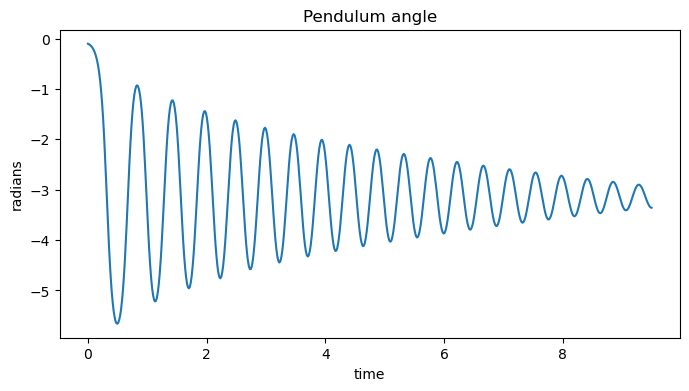

In [29]:
# Import Pandas and MatPlotLib
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [8, 4]

# Import the data from google drive using Pandas
furuta_data = pd.read_csv('https://drive.google.com/uc?export=dowload&id=1h_f8h-EVbuwfANGVZn-6tRICi-tEaMli')

plt.figure(1)
plt.clf()
plt.plot(furuta_data.t, furuta_data.rotorPhi)
plt.title("Rotor angle")
plt.xlabel("time")
plt.ylabel("radians")

plt.figure(2)
plt.clf()
plt.plot(furuta_data.t, furuta_data.pendulumPhi)
plt.title("Pendulum angle")
plt.xlabel("time")
plt.ylabel("radians")

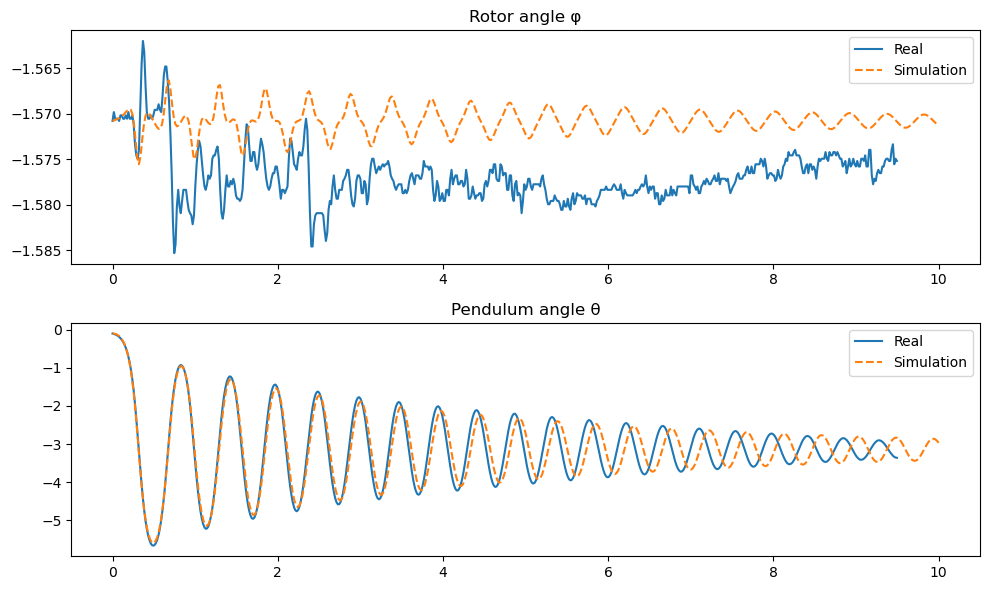

In [30]:
# Load simulation CSV
sim_phi   = pd.read_csv('results/Phi.csv', skiprows=1)
sim_theta = pd.read_csv('results/Theta.csv', skiprows=1)

sim_phi.columns   = ['time', 'phi']
sim_theta.columns = ['time', 'theta']

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# Real data
axes[0].plot(furuta_data.t, furuta_data.rotorPhi, label='Real')
axes[0].plot(sim_phi['time'], sim_phi['phi'], label='Simulation', linestyle='--')
axes[0].set_title('Rotor angle φ')
axes[0].legend()

axes[1].plot(furuta_data.t, furuta_data.pendulumPhi, label='Real')
axes[1].plot(sim_theta['time'], sim_theta['theta'], label='Simulation', linestyle='--')
axes[1].set_title('Pendulum angle θ')
axes[1].legend()

plt.tight_layout()
plt.show()

In [31]:
from scipy.signal import find_peaks
import numpy as np

# Find peaks in the real pendulum data
real_peaks_idx, _ = find_peaks(furuta_data.pendulumPhi)
real_peaks_t = furuta_data.t.values[real_peaks_idx]
real_peaks_v = furuta_data.pendulumPhi.values[real_peaks_idx]

# Find peaks in the simulation
sim_peaks_idx, _ = find_peaks(sim_theta.theta)
sim_peaks_t = sim_theta.time.values[sim_peaks_idx]
sim_peaks_v = sim_theta.theta.values[sim_peaks_idx]

# Frequency: average time between consecutive peaks
real_freq = 1 / np.mean(np.diff(real_peaks_t))
sim_freq  = 1 / np.mean(np.diff(sim_peaks_t))

print(f"Real frequency:  {real_freq:.3f} Hz")
print(f"Sim frequency:   {sim_freq:.3f} Hz")

# Amplitude decay: fit exponential to peak amplitudes
# A(t) = A0 * exp(-lambda * t)  →  log(A) = log(A0) - lambda*t
real_lambda = np.polyfit(real_peaks_t, np.log(np.abs(real_peaks_v)), 1)[0]
sim_lambda  = np.polyfit(sim_peaks_t,  np.log(np.abs(sim_peaks_v)),  1)[0]

print(f"Real decay rate: {real_lambda:.4f}")
print(f"Sim decay rate:  {sim_lambda:.4f}")

Real frequency:  2.132 Hz
Sim frequency:   2.088 Hz
Real decay rate: 0.1117
Sim decay rate:  0.0942


## Task 2 — Single Pendulum with Disturbances

Simulating `FurutaPendulum.mo` with damping constants `d_phi = 0.05`, `d_theta = 4e-6`.
Starting from downright position. Two disturbances applied: amplitude 0.025 and 0.06.

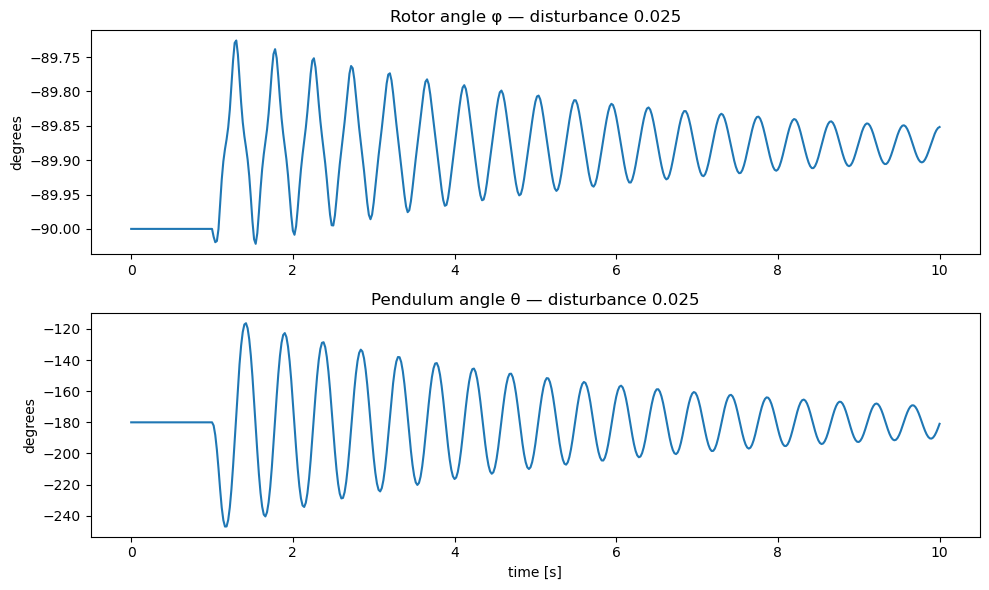

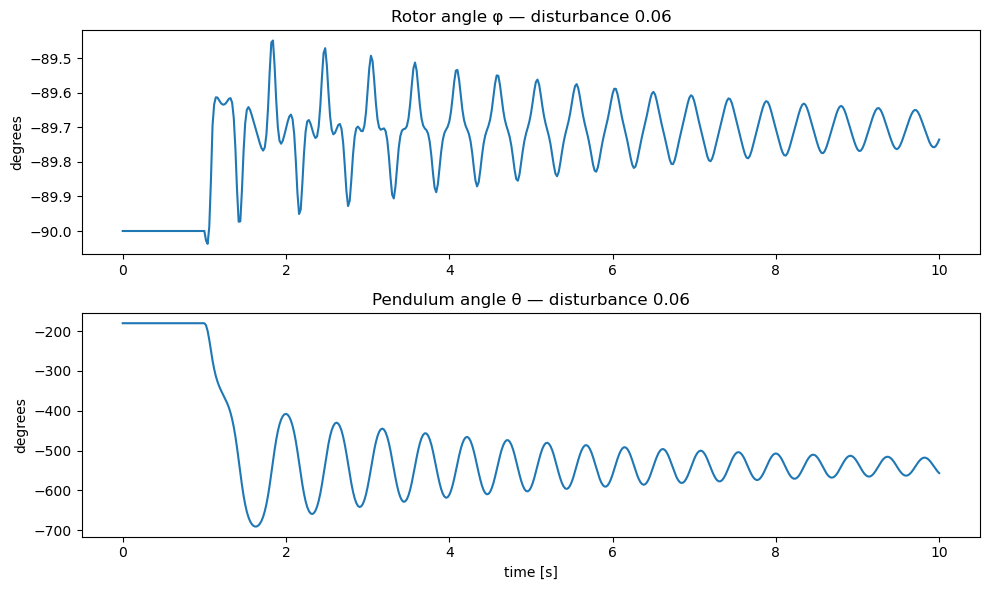

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

def load_and_rename(phi_file, theta_file):
    phi = pd.read_csv(phi_file, skiprows=1)
    theta = pd.read_csv(theta_file, skiprows=1)
    phi.columns = ['time', 'phi']
    theta.columns = ['time', 'theta']
    return phi, theta

def plot_task2(phi, theta, title):
    fig, axes = plt.subplots(2, 1, figsize=(10, 6))
    axes[0].plot(phi.time, phi.phi)
    axes[0].set_title(f'Rotor angle φ — {title}')
    axes[0].set_ylabel('degrees')
    axes[1].plot(theta.time, theta.theta)
    axes[1].set_title(f'Pendulum angle θ — {title}')
    axes[1].set_ylabel('degrees')
    plt.xlabel('time [s]')
    plt.tight_layout()
    plt.show()

# Small disturbance (amplitude = 0.025)
phi_small, theta_small = load_and_rename('results/task2_phi_small.csv', 'results/task2_theta_small.csv')
plot_task2(phi_small, theta_small, 'disturbance 0.025')

# Large disturbance (amplitude >= 0.06)
phi_large, theta_large = load_and_rename('results/task2_phi_large.csv', 'results/task2_theta_large.csv')
plot_task2(phi_large, theta_large, 'disturbance 0.06')


## Observations

For the small disturbance (0.025), the pendulum gets a small kick at t=1s and starts oscillating
around the downward position. The oscillations slowly die out due to friction. The rotor moves a
bit too, pulled by the coupling with the pendulum, but stays close to its initial position.

For the larger disturbance (0.06), the pendulum gets enough energy to go fully over the top and
spin around almost twice (~700°) before settling. This is very different from the small disturbance
case, instead of just swinging back and forth, the pendulum rotates.
The rotor also moves more here because the pendulum motion is much larger.

This shows that the system behaves very differently depending on how hard you kick it, which makes
sense since the equations of motion are nonlinear (sin and cos terms). A linear model around the
downward equilibrium would only be valid for small disturbances.


## Task 3 — Double Pendulum

Added a second pendulum arm in Modelon Impact with axis `n = {1, 0, 0}` (opposite to the first), so both pendulums swing *away* from each other when given the same initial angle.

Simulated with two disturbance amplitudes: small (`{0.025, 0, 0}`) and large (`{0.06, 0, 0}`).


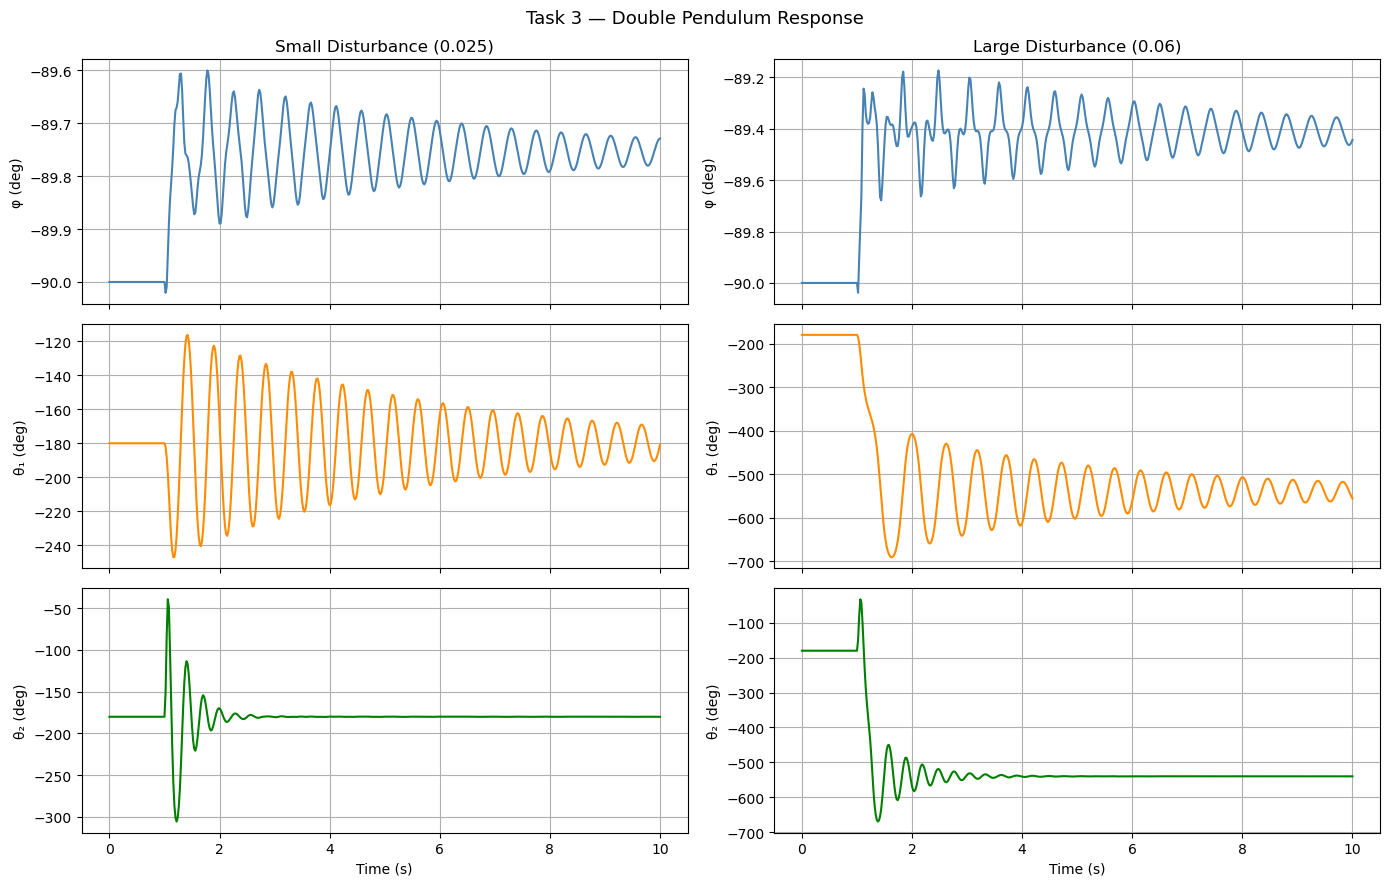

In [38]:
def load_signal(filepath, col_name):
    df = pd.read_csv(filepath, skiprows=1)
    df.columns = ['time', col_name]
    return df

# Small disturbance
phi_s    = load_signal('results/task3_phi_small.csv',    'phi')
theta1_s = load_signal('results/task3_theta1_small.csv', 'theta1')
theta2_s = load_signal('results/task3_theta2_small.csv', 'theta2')

# Large disturbance
phi_l    = load_signal('results/task3_phi_large.csv',    'phi')
theta1_l = load_signal('results/task3_theta1_large.csv', 'theta1')
theta2_l = load_signal('results/task3_theta2_large.csv', 'theta2')

fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex='col')

for col, (phi, theta1, theta2, title) in enumerate([
    (phi_s, theta1_s, theta2_s, 'Small Disturbance (0.025)'),
    (phi_l, theta1_l, theta2_l, 'Large Disturbance (0.06)'),
]):
    axes[0, col].plot(phi['time'],    phi['phi'],       color='steelblue')
    axes[0, col].set_title(title)
    axes[0, col].set_ylabel('φ (deg)')
    axes[0, col].grid(True)

    axes[1, col].plot(theta1['time'], theta1['theta1'], color='darkorange')
    axes[1, col].set_ylabel('θ₁ (deg)')
    axes[1, col].grid(True)

    axes[2, col].plot(theta2['time'], theta2['theta2'], color='green')
    axes[2, col].set_ylabel('θ₂ (deg)')
    axes[2, col].set_xlabel('Time (s)')
    axes[2, col].grid(True)

axes[0, 0].set_ylabel('φ (deg)')
axes[1, 0].set_ylabel('θ₁ (deg)')
axes[2, 0].set_ylabel('θ₂ (deg)')

plt.suptitle('Task 3 — Double Pendulum Response', fontsize=13)
plt.tight_layout()
plt.show()


### Observations

- θ₁ and θ₂ swing in **opposite directions**.
- Rotor φ moves very little (~0.4°) in both cases, the two pendulums cancel each other's torque.
- θ₂ damps faster than θ₁ due to both shorter arm (30 mm vs 75 mm, lower inertia) and 
  lower damping constant (d₂ = 2e-6 vs d₁ = 4e-6).


## Task 4 - Calculate the LQR gain vector
#### Create the linear state space model for the double pendulum, linearized around the downward position of the two pendulum arms

In [40]:
import numpy as np
import scipy.linalg

# Initialize constants
J = 125e-06
l1 = 0.075
l2 = 0.030
m1 = l1*np.pi*0.0025*0.0025*3700
m2 = l2*np.pi*0.0025*0.0025*3700
r = 0.043
g = 9.82

# Parameter declaration
a1 = J + m1*r*r
b1 = 1/3 * m1*l1*l1
c1 = 1/2 * m1*r*l1
d1 = 1/2 * m1*g*l1

a2 = J + m2*r*r
b2 = 1/3 * m2*l2*l2
c2 = 1/2 * m2*r*l2
d2 = 1/2 * m2*g*l2

D1 = a1*b1 - c1**2
D2 = a2*b2 - c2**2

# State Space declaration 
A = np.zeros((6,6))
A[0,1] = 1
A[1,2] = -(d1*c1)/D1
A[1,4] = -(d2*c2)/D2
A[2,3] = 1
A[3,2] = -(a1*d1)/D1
A[4,5] = 1
A[5,4] = -(a2*d2)/D2

B = np.zeros((6,1))
B[1,0] = b1/D1 + b2/D2
B[3,0] = c1/D1
B[5,0] = c2/D2

#### Using the defined cost matrices, calculate the LQR gain by solving the continuous-time algebraic Riccati equation

In [ ]:
# Define the cost matrices
Q = np.eye(6)
R = np.array([[1.0]])
R[0,0] = 100

# Solve the continuous-time algebraic Riccati equation
P = np.matrix(scipy.linalg.solve_continuous_are(A, B, Q, R))

# Calculate the LQR gain
K = scipy.linalg.solve(R, B.T*P)

print(K)

[-2.41971718e+03 +0.j         -1.00000022e+00 +0.j
 -5.90160905e+00+16.98869953j -5.90160905e+00-16.98869953j
 -2.88013405e+00+13.93638711j -2.88013405e+00-13.93638711j]
[[0.1        0.10653485 0.80278977 0.07639092 2.21698017 0.01419384]]


## Observations

We set `R = 100` instead of the default `1e-4`. The default value produces very large gains (K ≈ 100), which cause numerical instability in the simulation. With `R = 100`, the gains are around 0.1, making the system much easier to simulate accurately.

The resulting gain vector is:

**K = [0.1, 0.03018962, 0.10349668, -0.00030896, 0.1051762, -0.00284298]**

I also noticed that `pendulumAxis2` uses `n = {1, 0, 0}` (opposite to `pendulumAxis` with `n = {-1, 0, 0}`), so `theta2` and `dtheta2` are measured in the opposite direction compared to what the state-space model assumes. The fix was to negate them in the controller:


```x = {phi + 3.14/2, dphi, theta1 + 3.14, dtheta1, -(theta2 + 3.14), -dtheta2}```

The simulation used the Radau5ODE solver and a small disturbance of `{0.001, 0, 0}`.

In [54]:
# Verify closed-loop stability
import numpy as np

K_used = np.array([[0.1, 0.03018962, 0.10349668, -0.00030896, 0.1051762, -0.00284298]])

A_cl = A - B @ K_used
eigenvalues = np.linalg.eigvals(A_cl)
print("Closed-loop eigenvalues:")
for e in eigenvalues:
    print(f"  {e:.4f}")
print(f"\nAll stable (Re < 0): {all(e.real < 0 for e in eigenvalues)}")


Closed-loop eigenvalues:
  -416.0837+0.0000j
  -2.2908+22.9346j
  -2.2908-22.9346j
  -3.5303+0.0000j
  -0.7726+14.2309j
  -0.7726-14.2309j

All stable (Re < 0): True


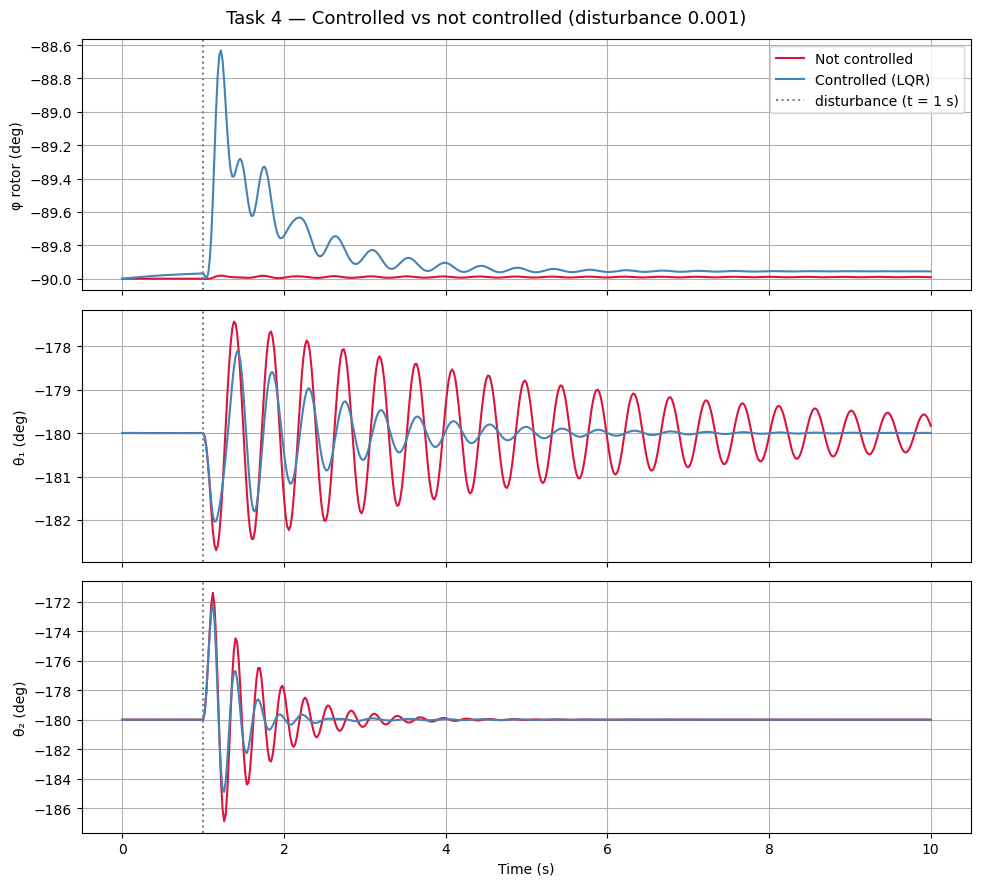

In [56]:
# Plot Task 4 simulation: controlled (LQR) vs not controlled, disturbance 0.001
cols = ['time', 'theta1', 'theta2', 'phi']
ctrl   = pd.read_csv('results/task4_0.001_controlled.csv',     skiprows=1)
noctrl = pd.read_csv('results/task4_0.001_not_controlled.csv', skiprows=1)
ctrl.columns   = cols
noctrl.columns = cols

signals = [('phi',    'φ rotor (deg)'),
           ('theta1', 'θ₁ (deg)'),
           ('theta2', 'θ₂ (deg)')]

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for ax, (col, label) in zip(axes, signals):
    ax.plot(noctrl['time'], noctrl[col], color='crimson',   label='Not controlled')
    ax.plot(ctrl['time'],   ctrl[col],   color='steelblue', label='Controlled (LQR)')
    ax.axvline(1.0, color='gray', linestyle=':', label='disturbance (t = 1 s)')
    ax.set_ylabel(label)
    ax.grid(True)

axes[0].legend(loc='best')
axes[2].set_xlabel('Time (s)')

plt.suptitle('Task 4 — Controlled vs not controlled (disturbance 0.001)', fontsize=13)
plt.tight_layout()
plt.show()


### Observations

The plots compare the double pendulum with and without the LQR controller. In both runs the same small disturbance (0.001) is applied at t = 1 s, starting from the downward position.

**Pendulum arms (θ₁, θ₂).** The controller damps the oscillations of both arms much faster than friction alone:
- θ₁ (the long arm) shows the clearest effect. Without control it is still swinging by about 0.6° after t = 8 s. With control it settles within about 5 s, and after t = 8 s the deviation is almost 0.
- θ₂ (the short arm) already dies out quickly without control, because of its lower inertia and damping. The controller still speeds it up, from about 4 s to about 2.4 s before it stays at almost 0 equilibrium.
- The peak amplitudes are similar in both runs, since they are set by the initial kick. The difference is in how fast the swings decay afterwards.

**Rotor (φ).** The rotor behaves very differently in the two runs:
- Without control, the rotor hardly moves. The controller is off, so nothing drives the rotor, and the only movement comes from the reaction torque of the swinging arms. This is why the uncontrolled rotor curve looks almost flat.
- With control, the rotor moves. This is intentional since the controller applies motor torque to the rotor to counteract the arm swings, so the rotor moves more because it is the actuator. The movement then dies out and the rotor settles close to its starting position.

## Task 5 - Stabilising Controller (Upright Position)

We now design an LQR controller to balance both pendulums in the **upright** position (θ = 0) instead of the downward one. 

For the upright equilibrium, the signs of the gravity terms in the A matrix flip compared to the downward case, the pendulums are now in an unstable equilibrium and gravity acts as a destabilising force.


In [ ]:
# State space for upward equilibrium — gravity terms flip sign
A_up = np.zeros((6,6))
A_up[0,1] = 1
A_up[1,2] = -(d1*c1)/D1
A_up[1,4] = -(d2*c2)/D2
A_up[2,3] = 1
A_up[3,2] = +(a1*d1)/D1   # sign flipped
A_up[4,5] = 1
A_up[5,4] = +(a2*d2)/D2   # sign flipped

# B for upright equilibrium (manual Eq. 4: the gamma coupling term flips sign)
B_up = np.zeros((6,1))
B_up[1,0] = b1/D1 + b2/D2   # unchanged
B_up[3,0] = -c1/D1           # sign flipped
B_up[5,0] = -c2/D2           # sign flipped

# Cost matrices
Q_up = np.eye(6)
R_up = np.zeros((1,1))
R_up[0,0] = 10

# Solve Riccati equation
P_up = np.matrix(scipy.linalg.solve_continuous_are(A_up, B_up, Q_up, R_up))
K_up = scipy.linalg.solve(R_up, B_up.T * P_up)
print("K (upward):", K_up)

# Check closed-loop stability (use B_up, the same B the gain was designed with)
A_cl_up = A_up - B_up @ K_up
eigs_up = np.linalg.eigvals(A_cl_up)
print("All stable:", all(e.real < 0 for e in eigs_up))


### Observations

The controller is implemented in Modelica with the upward setpoint (`theta1` and `theta2` offsets removed) and the same theta2 sign fix as Task 4. Initial conditions are set very close to upright (θ₁ = θ₂ = 0.01 rad) with a small disturbance of `{0.001, 0, 0}`.

![Task 5 - Upright LQR controller result](task5_result.png)


The upright controller works for very small disturbances, but the system falls if the perturbation is too large. This is expected — the LQR is based on a **linearised** model, which is only valid close to the equilibrium point. Any angle deviation beyond a few degrees takes the system outside the linear regime and the controller can no longer compensate.
